# Notebook 7. RAG multimodal

**Duración prevista en clase: 1 h 30 min** · **Dificultad: alta**

Objetivo: recuperar páginas cuyo contenido está en la imagen y no en el texto (el diagrama, el cronograma, el
calendario de colores) y fusionarlas con el RAG de texto.

- Preguntas a un VLM sobre lo que solo se ve en la imagen.
- (a) Descripción de cada página generada por el VLM y búsqueda con el RAG de texto.
- (b) SigLIP 2: buscar imágenes de páginas y figuras con una pregunta en español.
- **V7**: V6 + índice de unidades visuales fusionado con el de texto.

La comparación con CLIP, ColPali/ColQwen y el codificador de imagen por dentro están en
`anexos/A4_multimodal_avanzado.ipynb`.

Referencias:
- SigLIP 2: https://arxiv.org/abs/2502.14786
- ColPali: https://arxiv.org/abs/2407.01449
- RAG multimodal: https://www.zeroentropy.dev/concepts/multimodal-rag/
- Imágenes en OpenRouter: https://openrouter.ai/docs

In [1]:
from rag_lab import CFG, set_seeds, summary

# CFG.FAST_MODE = False  # corpus de control completo (por defecto se lee FAST_MODE de .env)
# CFG.DOC_PATH = CFG.DATA_DIR / "mi_documento.pdf"  # cualquier PDF sirve
set_seeds()
summary()

Documento:   /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/data/documento.pdf (existe)
FAST_MODE:   True
Dispositivo: cuda
GEN_MODEL:   google/gemini-3.1-flash-lite
JUDGE_MODEL: openai/gpt-5-mini
VLM_MODEL:   google/gemini-3.1-flash-lite
OpenRouter:  clave configurada


Trazas:      jsonl /home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/trazas/trazas.jsonl  (alumno: profesor)


/home/mikel/github/2627/iab4/reto-1/semana2-reorganizada/rag_lab/tracing.py:49: UserWarning: No se pudo conectar con Langfuse ([Errno 111] Connection refused): las trazas se guardan en JSONL.
  warnings.warn(f"No se pudo conectar con Langfuse ({e}): las trazas se guardan en JSONL.")


## 1. Preguntas al VLM sobre el PDF

En el notebook 6 el VLM leía texto. Ahora le preguntamos por lo que solo está en la imagen: marcas, colores,
flechas. Compara cada respuesta con la imagen: el VLM también se equivoca, sobre todo al contar celdas en tablas densas.

In [2]:
import matplotlib.pyplot as plt
from PIL import Image
from rag_lab import llm, pdf

images = pdf.render_pages()

In [3]:
def ask(page_n, question):
    r = llm.vision(question, [images[page_n]], max_tokens=600, step="vlm_demo")
    print(f"[página {page_n}] {question}\n{r.text}\n({r.input_tokens} tokens de entrada, {r.cost_usd:.5f} USD)\n")

ask(1, "Describe en dos frases el diagrama de esta página y las palabras que aparecen en él.")
ask(13, "En el cronograma de 24 meses, ¿en qué meses tiene marcas (X) la FASE 4? Lista los meses.")
ask(20, "En la tabla de desglose por trimestre, ¿qué trimestres están coloreados en verde en la fila DIFUSION?")

[página 1] Describe en dos frases el diagrama de esta página y las palabras que aparecen en él.
El diagrama muestra un símbolo de infinito que representa el ciclo de vida de MLOps, integrando las fases de diseño, despliegue, entrenamiento, prueba y mantenimiento. Las palabras que aparecen en el gráfico son "ML", "Ops", "DEPLOY", "DESIGN", "TEST &" y "TRAIN", junto con "MAINTAIN" en la intersección central.
(1109 tokens de entrada, 0.00039 USD)

[página 13] En el cronograma de 24 meses, ¿en qué meses tiene marcas (X) la FASE 4? Lista los meses.
Basado en el cronograma proporcionado, la **FASE 4** tiene marcas (X) en los siguientes meses:

*   **M9**
*   **M10**
*   **M11**
*   **M12**
*   **M13**
*   **M14**
*   **M15**
*   **M16**
*   **M17**
*   **M18**
(1121 tokens de entrada, 0.00044 USD)

[página 20] En la tabla de desglose por trimestre, ¿qué trimestres están coloreados en verde en la fila DIFUSION?
En la tabla de desglose por trimestre, en la fila **DIFUSION**, los trimestres col

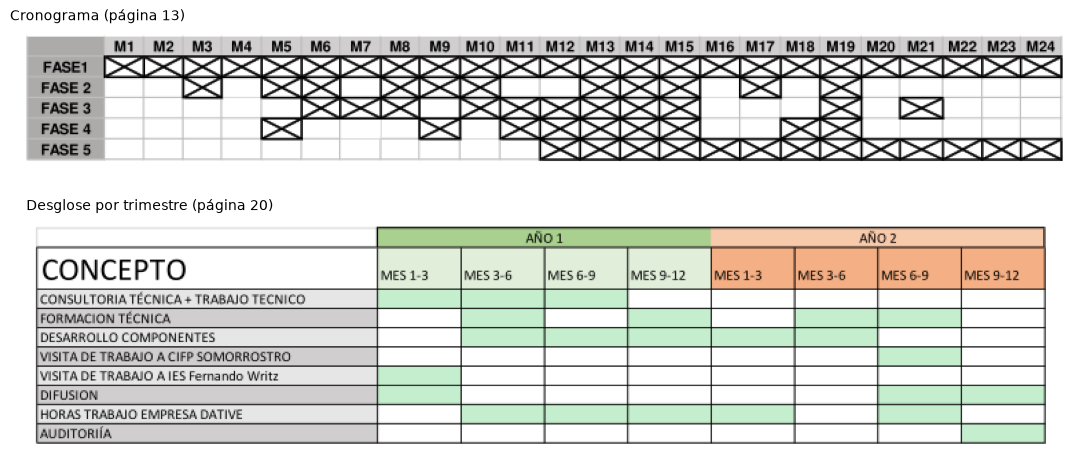

In [4]:
# Recortes para comprobar las respuestas a ojo
p13, p20 = Image.open(images[13]), Image.open(images[20])
fig, panels = plt.subplots(2, 1, figsize=(11, 5))
panels[0].imshow(p13.crop((60, 435, p13.size[0] - 50, 540)))
panels[1].imshow(p20.crop((85, 990, p20.size[0] - 70, 1160)))
for panel, title in zip(panels, ["Cronograma (página 13)", "Desglose por trimestre (página 20)"]):
    panel.set_title(title, fontsize=10, loc="left")
    panel.axis("off")
plt.tight_layout()
plt.show()

Cuenta tú las marcas de la FASE 4 y las celdas verdes de la fila DIFUSION en los recortes y compáralas con las
respuestas del VLM. Este tipo de error es la razón de que las preguntas visuales de `preguntas.jsonl` se revisen a mano.

In [5]:
my_question = "En la matriz de tareas por línea y fase, ¿qué tareas tiene la LÍNEA 3 en la FASE 1?"
if my_question:
    ask(12, my_question)
else:
    print("Completa el TODO: escribe my_question.")

[página 12] En la matriz de tareas por línea y fase, ¿qué tareas tiene la LÍNEA 3 en la FASE 1?
En la matriz de tareas, para la **LÍNEA 3** en la **FASE 1**, las tareas asignadas son: **T9, T10, T11, T12**.
(1119 tokens de entrada, 0.00035 USD)



## 2. Tres formas de indexar lo visual

| Enfoque | Qué se indexa | Vectores por página | Dónde |
|---|---|---|---|
| (a) Descripción con un VLM | El texto que el VLM escribe sobre la página | Los del RAG de texto | Sección 3 |
| (b) CLIP / SigLIP | La imagen entera como un único vector | 1 | Sección 4 |
| (c) ColPali / ColQwen | Cada parche de la página, con interacción tardía tipo ColBERT | Cientos o miles | Anexo A4 (necesita un servidor con GPU) |

In [6]:
import pandas as pd
from rag_lab import evaluation, models, multimodal, results, versions
from rag_lab.indexes import BM25Index, DenseIndex
from rag_lab.retrieval import rrf

questions = evaluation.load_questions()
visuals = [p for p in questions if p["tipo"] == "visual"]

def page_of(uid):
    return int(uid.split("-")[1])

def correct_position(ranking_ids, correct):
    for i, uid in enumerate(ranking_ids, start=1):
        if page_of(uid) in correct:
            return i
    return None

def metrics(rankings):
    rows = [{"recuperadas": [[page_of(u)] for u in r], "correctas": p["paginas"]} for r, p in zip(rankings, visuals)]
    return evaluation.evaluate_retrieval(rows)

print(len(visuals), "preguntas visuales:", [(p["id"], p["paginas"], p.get("elemento")) for p in visuals])

6 preguntas visuales: [('q15', [1], 'diagrama'), ('q16', [12], 'matriz'), ('q17', [13], 'cronograma'), ('q18', [20], 'cronograma'), ('q19', [1], 'diagrama'), ('q20', [12], 'matriz')]


## 3. (a) Descripción de páginas con el VLM

El VLM describe cada página y transcribe lo que solo se ve en la imagen (marcas, colores, flechas).
Cada descripción es una unidad de texto con su página: se indexa con BM25 y denso como cualquier fragmento.
Las descripciones se generan una vez y quedan en la caché del LLM.

In [7]:
descriptions = multimodal.describe_pages()
desc_units = multimodal.visual_units(descriptions)
print(desc_units[12]["texto"][:1500])

Descripción de la página 13:
Este documento contiene tablas y un cronograma. A continuación se detalla su contenido:

**1. Tabla de porcentajes de participación:**
Muestra el nivel de intervención de cada entidad por fase:
*   **Participantes:** IES Fernando Wirtz Suárez, CFS, Dative.
*   **Fase 1:** 25% (IES), 30% (CFS), 45% (Dative).
*   **Fase 2:** 25% (IES), 30% (CFS), 45% (Dative).
*   **Fase 3:** 25% (IES), 30% (CFS), 45% (Dative).
*   **Fase 4:** 30% (IES), 60% (CFS), 10% (Dative).
*   **Fase 5:** 33% (IES), 33% (CFS), 33% (Dative).

**2. Cronograma de actividades (24 meses):**
Indica los meses de ejecución de cada fase mediante celdas marcadas con una "X":
*   **FASE 1:** Marcada de M1 a M12.
*   **FASE 2:** Marcada de M1 a M6.
*   **FASE 3:** Marcada de M5 a M18.
*   **FASE 4:** Marcada de M9 a M21.
*   **FASE 5:** Marcada de M17 a M24.

**3. Tabla de resultados y productos esperados (Línea 1):**
Título: "5. RESULTADOS Y PRODUCTOS ESPERADOS POR LÍNEA DE ACTUACIÓN".
Línea 1: "I

In [8]:
dense_desc = DenseIndex("descripciones", desc_units)
bm25_desc = BM25Index(desc_units)

def search_descriptions(question, k=10):
    return [u for u, _ in rrf([dense_desc.search(question, k), bm25_desc.search(question, k)])][:k]

rank_desc = [search_descriptions(p["pregunta"]) for p in visuals]
metrics(rank_desc)

{'recall@5': 1.0, 'recall@10': 1.0, 'MRR@10': 1.0}

## 4. (b) SigLIP 2: un vector por imagen

Un único vector por imagen (página entera o figura recortada por Docling) y otro para la pregunta, en el mismo
espacio. SigLIP 2 es multilingüe, así que la pregunta puede ir en español. Indexar es barato, pero un solo vector
resume mal una página llena de texto.

In [9]:
img_units = multimodal.image_units(with_figures=True)
print(len(img_units), "imágenes:", sum(u["id"].startswith("figura") for u in img_units), "figuras y el resto páginas")

def to_page(ranking):
    """Pasa un ranking de imágenes a un ranking de páginas (una figura cuenta como su página)."""
    by_id = {u["id"]: u for u in img_units}
    seen_pages, output = set(), []
    for uid, _ in ranking:
        page = by_id[uid].get("figura_de", uid)
        if page not in seen_pages:
            seen_pages.add(page)
            output.append(page)
    return output

siglip = multimodal.ImageIndex(img_units, "siglip")
rank_img = [to_page(siglip.search(p["pregunta"], 20))[:10] for p in visuals]
del siglip
models.release()
metrics(rank_img)

22 imágenes: 2 figuras y el resto páginas


{'recall@5': 1.0, 'recall@10': 1.0, 'MRR@10': 0.8888888888888888}

## 5. V7: V6 + unidades visuales

Las descripciones de página entran en el índice híbrido junto a los fragmentos de texto enriquecidos de V6, y el
ranking de imágenes de SigLIP 2 se fusiona con RRF antes del reranker. El reranker lee la descripción
de cada página, así que una página visual compite con texto que la describe.

In [10]:
structured = versions.pdf_fragments("cabeceras")
enriched = versions.enrich(structured, versions.document_title(versions.pdf.clean_pages()))
v7 = multimodal.Multimodal(enriched, descriptions, image_family="siglip")
eval_v7 = evaluation.evaluate_rag(v7, questions)
results.table("pdf").loc[["V6", "V7"], ["tecnica", "recall@5", "recall@5_texto", "recall@5_tabla",
                                           "recall@5_visual", "MRR@10", "fidelidad", "relevancia_contexto",
                                           "latencia_p50_ms", "coste_usd"]].round(3)

,tecnica,recall@5,recall@5_texto,recall@5_tabla,recall@5_visual,MRR@10,fidelidad,relevancia_contexto,latencia_p50_ms,coste_usd
version,,,,,,,,,,
V6,"V5 + multi-query (3 reformulaciones, RRF)",0.9,1.0,1.0,0.667,0.838,0.8,0.80,3597.190,0.019
V7,V6 + unidades visuales (descripción VLM + SIGL...,1.0,1.0,1.0,1.000,0.935,0.9,0.85,3813.835,0.022


Qué enfoque encontró la página correcta de cada pregunta visual: posición de la primera unidad de la página
correcta en el top-10 (vacío = no aparece).

In [11]:
v6 = versions.build("V6")
eval_v6 = evaluation.evaluate_rag(v6, visuals, with_judge=False, register=False)["detalle"]
det_v7 = eval_v7["detalle"].set_index("id")

def pages_position(retrieved, correct):
    return next((i for i, u in enumerate(retrieved, 1) if set(u) & set(correct)), None)

rows = []
for i, p in enumerate(visuals):
    row = {"id": p["id"], "elemento": p.get("elemento"), "página": p["paginas"][0],
            "V6 (texto)": pages_position(eval_v6.iloc[i]["recuperadas"], p["paginas"]),
            "(a) descripción": correct_position(rank_desc[i], p["paginas"]),
            "(b) siglip": correct_position(rank_img[i], p["paginas"])}
    row["V7"] = pages_position(det_v7.loc[p["id"], "recuperadas"], p["paginas"])
    rows.append(row)
pd.DataFrame(rows).set_index("id")

,elemento,página,V6 (texto),(a) descripción,(b) siglip,V7
id,,,,,,
q15,diagrama,1,NaN,1,1,1
q16,matriz,12,1.0,1,1,1
q17,cronograma,13,2.0,1,1,1
q18,cronograma,20,1.0,1,1,2
q19,diagrama,1,NaN,1,1,1
q20,matriz,12,1.0,1,3,1


In [12]:
det_v7.loc[[p["id"] for p in visuals], ["pregunta", "respuesta", "fidelidad", "relevancia_contexto"]]

,pregunta,respuesta,fidelidad,relevancia_contexto
id,,,,
q15,"En el diagrama de infinito de MLOps, ¿qué pala...",No aparece en el documento.,0,0
q16,¿Qué tareas están asignadas a la intersección ...,Las tareas asignadas a la intersección entre l...,1,1
q17,"En el cronograma de actividades, ¿qué celdas e...","En la Fase 3, las celdas marcadas con una ""X"" ...",1,1
q18,"En el cronograma de desglose por trimestre, ¿q...",No aparece en el documento.,1,0
q19,"En el diagrama de infinito de MLOps, ¿qué pala...",No aparece en el documento.,0,0
q20,¿Qué tareas están asignadas a la intersección ...,La tarea asignada a la intersección entre la F...,1,1


In [13]:
from rag_lab import llm, pdf

p = visuals[0]
first_page = det_v7.loc[p["id"], "recuperadas"][0][0]
answer_text = llm.vision(p["pregunta"], [pdf.render_pages()[first_page]], max_tokens=400).text
print(p["pregunta"], "->", answer_text or "Completa el TODO")

En el diagrama de infinito de MLOps, ¿qué palabra aparece escrita en la parte superior de la sección gris? -> En la parte superior de la sección gris del diagrama de infinito, aparece escrita la frase: **TEST &**


In [14]:
models.release()

## Qué hemos visto

- Un VLM responde preguntas sobre la imagen, pero se equivoca al contar: sus respuestas hay que revisarlas.
- Describir cada página con un VLM convierte la información visual en texto que el RAG ya sabe buscar.
- SigLIP da un vector por imagen: barato de indexar, pero grueso para páginas llenas de texto.
- Las unidades visuales se fusionan con las de texto con RRF y compiten en el mismo reranker.

## Ejercicio propuesto

Indexa por separado cada figura recortada por Docling con su propia descripción del VLM (en lugar de la página
entera) y compara el recall@5 de las preguntas visuales con el de V7.